In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import scipy
import plotly

print("Environment setup completed!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Environment setup completed!
Pandas version: 3.1.1
NumPy version: 2.5.4
Scikit-learn version: 1.9.1


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import scipy
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from pathlib import Path
import pandas as pd

# Locate the project root automatically
current_dir = Path.cwd()
possible_roots = [current_dir] + list(current_dir.parents)

project_root = next(
    (
        path for path in possible_roots
        if (path / "app.py").exists()
        and (path / "notebook").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Could not locate the project root.")

# Load the dataset using a relative path
dataset_path = project_root / "dataset" / "Online Retail.xlsx"

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {dataset_path}. "
        "Download it from UCI and place it inside the dataset folder."
    )

df = pd.read_excel(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (541909, 8)


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [10]:
# ============================================
# 4. CHECK DUPLICATE RECORDS
# ============================================

# Count the total number of duplicate rows
duplicate_count = df.duplicated().sum()

# Display the result
print("Total Duplicate Records:", duplicate_count)

# Calculate the percentage of duplicate records
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Duplicate Percentage:", round(duplicate_percentage, 2), "%")

Total Duplicate Records: 5268
Duplicate Percentage: 0.97 %


In [11]:
# ============================================
# 5. ANALYZE PRODUCT QUANTITY
# ============================================

# Display basic statistics of Quantity
print("Quantity Statistics:")
display(df["Quantity"].describe())

# Count transactions with negative quantities
negative_quantity = (df["Quantity"] < 0).sum()

# Count transactions with zero quantities
zero_quantity = (df["Quantity"] == 0).sum()

# Count transactions with positive quantities
positive_quantity = (df["Quantity"] > 0).sum()

print("Negative Quantity Records:", negative_quantity)
print("Zero Quantity Records:", zero_quantity)
print("Positive Quantity Records:", positive_quantity)

Quantity Statistics:


count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

Negative Quantity Records: 10624
Zero Quantity Records: 0
Positive Quantity Records: 531285


In [12]:
# ============================================
# 6. ANALYZE PRODUCT UNIT PRICE
# ============================================

# Display statistical information about product prices
print("Unit Price Statistics:")
display(df["UnitPrice"].describe())

# Count records with zero or negative prices
invalid_prices = (df["UnitPrice"] <= 0).sum()

# Count records with positive prices
valid_prices = (df["UnitPrice"] > 0).sum()

print("Invalid Price Records:", invalid_prices)
print("Valid Price Records:", valid_prices)

Unit Price Statistics:


count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

Invalid Price Records: 2517
Valid Price Records: 539392


In [13]:
# ============================================
# 7. IDENTIFY CANCELLED INVOICES
# ============================================

# Convert invoice numbers to strings for checking
invoice_numbers = df["InvoiceNo"].astype(str)

# Identify invoices beginning with the letter C
cancelled_invoices = invoice_numbers.str.startswith("C")

# Count cancelled and non-cancelled records
cancelled_count = cancelled_invoices.sum()
normal_count = (~cancelled_invoices).sum()

print("Cancelled Invoice Records:", cancelled_count)
print("Normal Invoice Records:", normal_count)

Cancelled Invoice Records: 9288
Normal Invoice Records: 532621


In [14]:
# ============================================
# 8. CUSTOMER INFORMATION ANALYSIS
# ============================================

# Count total unique customers, excluding missing IDs
unique_customers = df["CustomerID"].nunique()

# Count records with missing customer IDs
missing_customer_ids = df["CustomerID"].isnull().sum()

# Count unique products
unique_products = df["StockCode"].nunique()

# Count unique countries
unique_countries = df["Country"].nunique()

print("Total Unique Customers:", unique_customers)
print("Missing Customer IDs:", missing_customer_ids)
print("Total Unique Products:", unique_products)
print("Total Countries:", unique_countries)

Total Unique Customers: 4372
Missing Customer IDs: 135080
Total Unique Products: 4070
Total Countries: 38


## 4. Investigating Data Quality Issues

In this section, we inspect duplicate transactions, product returns,
invalid prices and cancelled invoices before cleaning the dataset.

In [15]:
# ============================================
# 9. INSPECT DUPLICATE RECORDS
# ============================================

# Display the first five duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows.head(10))

# Check whether duplicate records are exact matches
print("Total duplicate rows:", duplicate_rows.shape[0])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


Total duplicate rows: 10147


In [16]:
# ============================================
# 10. INSPECT MISSING CUSTOMER IDs
# ============================================

# Extract transactions where CustomerID is missing
missing_customer_data = df[df["CustomerID"].isnull()]

# Display the first ten records
display(missing_customer_data.head(10))

# Calculate the percentage of missing Customer IDs
missing_percentage = (missing_customer_data.shape[0] / len(df)) * 100

print("Missing Customer ID Percentage:", round(missing_percentage, 2), "%")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom


Missing Customer ID Percentage: 24.93 %


In [17]:
# ============================================
# 11. INSPECT NEGATIVE QUANTITIES
# ============================================

# Extract transactions with negative quantities
return_transactions = df[df["Quantity"] < 0]

# Display sample return transactions
display(return_transactions.head(10))

# Check how many unique invoices contain negative quantities
print(
    "Unique invoices with negative quantities:",
    return_transactions["InvoiceNo"].nunique()
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Unique invoices with negative quantities: 5172


In [18]:
# ============================================
# 12. INSPECT INVALID PRODUCT PRICES
# ============================================

# Extract transactions with zero or negative prices
invalid_price_data = df[df["UnitPrice"] <= 0]

# Display sample records
display(invalid_price_data.head(10))

# Check the different price values
print("Invalid Price Values:")
display(invalid_price_data["UnitPrice"].value_counts().head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


Invalid Price Values:


UnitPrice
 0.00        2515
-11062.06       2
Name: count, dtype: int64

In [19]:
# ============================================
# 13. INSPECT CANCELLED INVOICES
# ============================================

# Identify cancelled invoice records
cancelled_data = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

# Display sample cancelled transactions
display(cancelled_data.head(10))

# Count unique cancelled invoices
print(
    "Unique Cancelled Invoices:",
    cancelled_data["InvoiceNo"].nunique()
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Unique Cancelled Invoices: 3836


# 5. DATA CLEANING AND PREPROCESSING

In this section, we clean the raw dataset by removing duplicate
records, cancelled transactions, missing customer IDs and invalid
purchase records.

We preserve the original dataset and perform all cleaning
operations on a separate DataFrame.

In [20]:
# ============================================
# 14. REMOVE DUPLICATE RECORDS
# ============================================

# Create a copy of the original dataset
df_clean = df.copy()

# Store the initial number of records
initial_records = len(df_clean)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Calculate how many records were removed
duplicates_removed = initial_records - len(df_clean)

print("Duplicate Records Removed:", duplicates_removed)
print("Remaining Records:", len(df_clean))

Duplicate Records Removed: 5268
Remaining Records: 536641


In [21]:
# ============================================
# 15. REMOVE CANCELLED INVOICES
# ============================================

# Identify invoices beginning with the letter C
cancelled_mask = df_clean["InvoiceNo"].astype(str).str.startswith("C")

# Count records belonging to cancelled invoices
cancelled_records_removed = cancelled_mask.sum()

# Keep only non-cancelled transactions
df_clean = df_clean[~cancelled_mask].copy()

print("Cancelled Invoice Records Removed:", cancelled_records_removed)
print("Remaining Records:", len(df_clean))

Cancelled Invoice Records Removed: 9251
Remaining Records: 527390


In [22]:
# ============================================
# 16. REMOVE MISSING CUSTOMER IDs
# ============================================

# Count records with missing CustomerID
missing_ids_removed = df_clean["CustomerID"].isnull().sum()

# Remove records without customer identification
df_clean = df_clean.dropna(subset=["CustomerID"]).copy()

print("Records with Missing Customer IDs Removed:", missing_ids_removed)
print("Remaining Records:", len(df_clean))

Records with Missing Customer IDs Removed: 134658
Remaining Records: 392732


In [23]:
# ============================================
# 17. REMOVE INVALID QUANTITIES
# ============================================

# Count transactions with zero or negative quantities
invalid_quantity_removed = (df_clean["Quantity"] <= 0).sum()

# Keep transactions with positive quantities only
df_clean = df_clean[df_clean["Quantity"] > 0].copy()

print("Invalid Quantity Records Removed:", invalid_quantity_removed)
print("Remaining Records:", len(df_clean))

Invalid Quantity Records Removed: 0
Remaining Records: 392732


In [24]:
# ============================================
# 18. REMOVE INVALID UNIT PRICES
# ============================================

# Count transactions with zero or negative prices
invalid_price_removed = (df_clean["UnitPrice"] <= 0).sum()

# Keep transactions with positive unit prices
df_clean = df_clean[df_clean["UnitPrice"] > 0].copy()

print("Invalid Price Records Removed:", invalid_price_removed)
print("Remaining Records:", len(df_clean))

Invalid Price Records Removed: 40
Remaining Records: 392692


In [25]:
# ============================================
# 19. DATA CLEANING SUMMARY
# ============================================

# Create a summary of all cleaning operations
cleaning_summary = pd.DataFrame({
    "Cleaning Operation": [
        "Original Dataset",
        "Duplicate Records Removed",
        "Cancelled Invoices Removed",
        "Missing Customer IDs Removed",
        "Invalid Quantities Removed",
        "Invalid Prices Removed",
        "Final Cleaned Dataset"
    ],

    "Records": [
        initial_records,
        duplicates_removed,
        cancelled_records_removed,
        missing_ids_removed,
        invalid_quantity_removed,
        invalid_price_removed,
        len(df_clean)
    ]
})

# Display the cleaning summary
display(cleaning_summary)

,Cleaning Operation,Records
0,Original Dataset,541909
1,Duplicate Records Removed,5268
2,Cancelled Invoices Removed,9251
3,Missing Customer IDs Removed,134658
4,Invalid Quantities Removed,0
5,Invalid Prices Removed,40
6,Final Cleaned Dataset,392692


In [26]:
# ============================================
# 20. VERIFY CLEANED DATASET
# ============================================

# Display the final dataset dimensions
print("Final Dataset Shape:", df_clean.shape)

# Check for remaining missing values
print("\nMissing Values:")
display(df_clean.isnull().sum())

# Check for remaining duplicates
print("\nRemaining Duplicate Records:", df_clean.duplicated().sum())

# Check for invalid quantities
print("\nInvalid Quantities:", (df_clean["Quantity"] <= 0).sum())

# Check for invalid prices
print("\nInvalid Prices:", (df_clean["UnitPrice"] <= 0).sum())

# Display the first five cleaned records
display(df_clean.head())

Final Dataset Shape: (392692, 8)

Missing Values:


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


Remaining Duplicate Records: 0

Invalid Quantities: 0

Invalid Prices: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [27]:
# ============================================
# 21. CALCULATE TOTAL TRANSACTION VALUE
# ============================================

# Calculate the total value of each transaction line
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Display the updated dataset
display(df_clean[[
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "UnitPrice",
    "TotalPrice",
    "CustomerID"
]].head())

print("TotalPrice column created successfully!")

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalPrice,CustomerID
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,17850.0
1,536365,71053,WHITE METAL LANTERN,6,3.39,20.34,17850.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,17850.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,17850.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34,17850.0


TotalPrice column created successfully!


# 6. EXPLORATORY DATA ANALYSIS (EDA)

Exploratory Data Analysis is performed to understand customer
purchasing behaviour, product demand and revenue patterns.

We use statistical analysis and visualizations to identify
useful business insights before building machine learning models.

In [28]:
# ============================================
# 22. PREPARE DATA FOR EXPLORATORY ANALYSIS
# ============================================

# Convert InvoiceDate into datetime format
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Extract useful date information
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month

# Calculate the total number of unique customers
total_customers = df_clean["CustomerID"].nunique()

# Calculate the total number of unique products
total_products = df_clean["StockCode"].nunique()

# Calculate total revenue from valid purchase transactions
total_revenue = df_clean["TotalPrice"].sum()

# Display the results
print("Total Unique Customers:", total_customers)
print("Total Unique Products:", total_products)
print("Total Revenue: £", round(total_revenue, 2))

# Check the data type of InvoiceDate
print("\nInvoiceDate Data Type:", df_clean["InvoiceDate"].dtype)

Total Unique Customers: 4338
Total Unique Products: 3665
Total Revenue: £ 8887208.89

InvoiceDate Data Type: datetime64[us]


Top 10 Best-Selling Products:


Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64

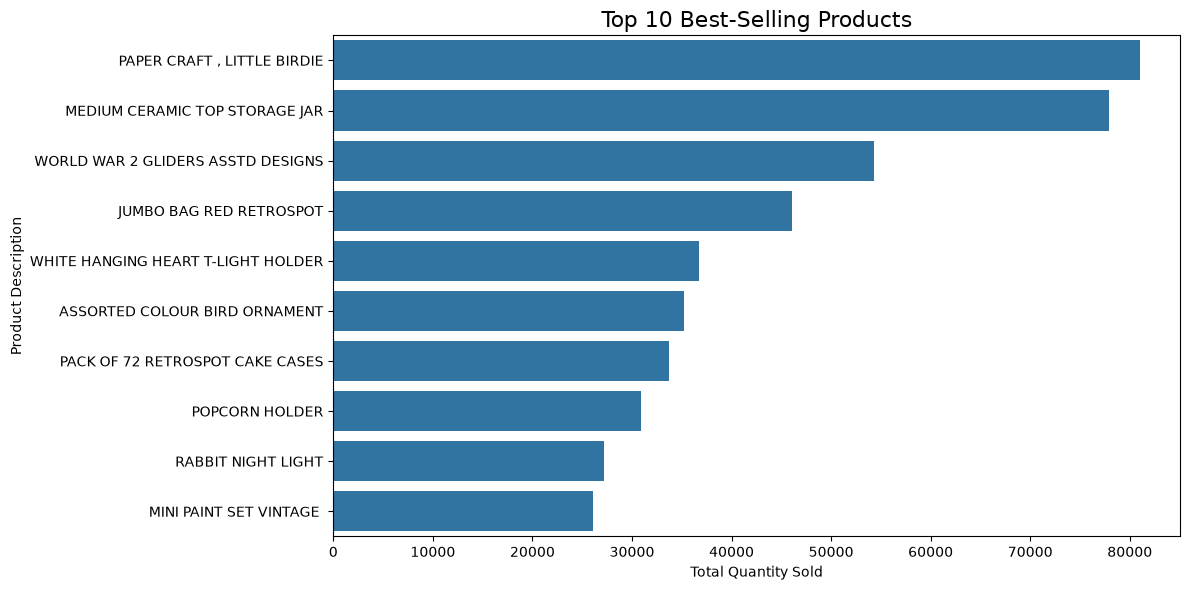

In [29]:
# ============================================
# 23. TOP 10 BEST-SELLING PRODUCTS
# ============================================

# Group transactions by product description
# Calculate the total quantity sold for each product
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 products
print("Top 10 Best-Selling Products:")
display(top_products)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

# Add chart title and labels
plt.title("Top 10 Best-Selling Products", fontsize=16)
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Description")

# Adjust layout and display chart
plt.tight_layout()
plt.show()

Top 10 Countries by Revenue:


Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalPrice, dtype: float64

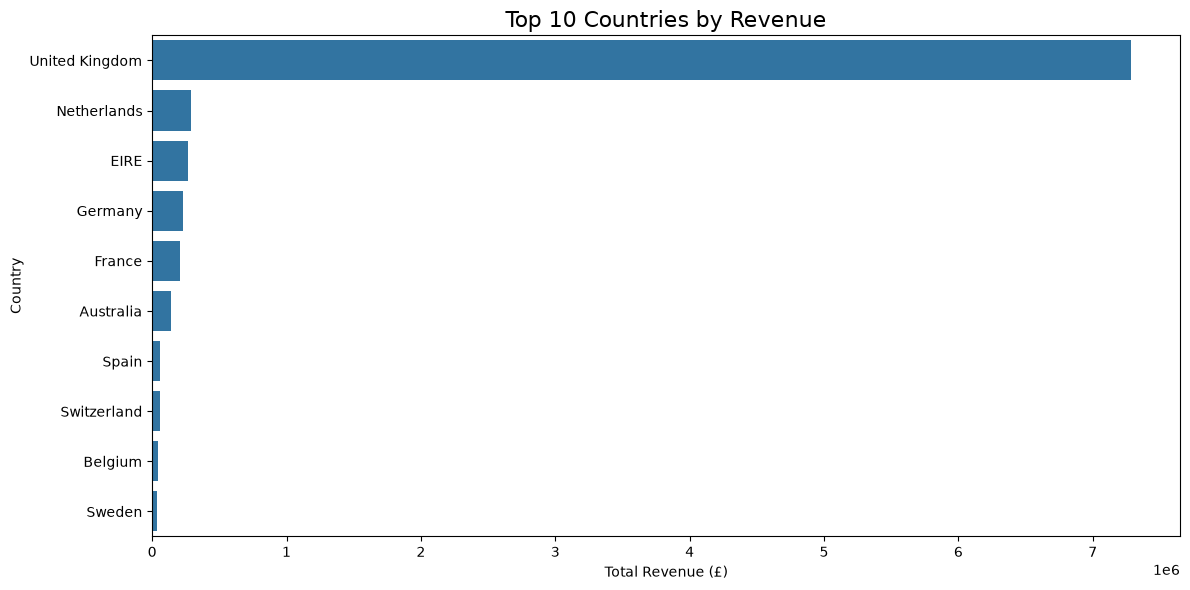

In [30]:
# ============================================
# 24. TOP 10 COUNTRIES BY REVENUE
# ============================================

# Group transactions by country
# Calculate total revenue generated by each country
country_revenue = (
    df_clean.groupby("Country")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 countries
print("Top 10 Countries by Revenue:")
display(country_revenue)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_revenue.values,
    y=country_revenue.index
)

# Add chart title and labels
plt.title("Top 10 Countries by Revenue", fontsize=16)
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

Monthly Revenue:


InvoiceDate
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Name: TotalPrice, dtype: float64

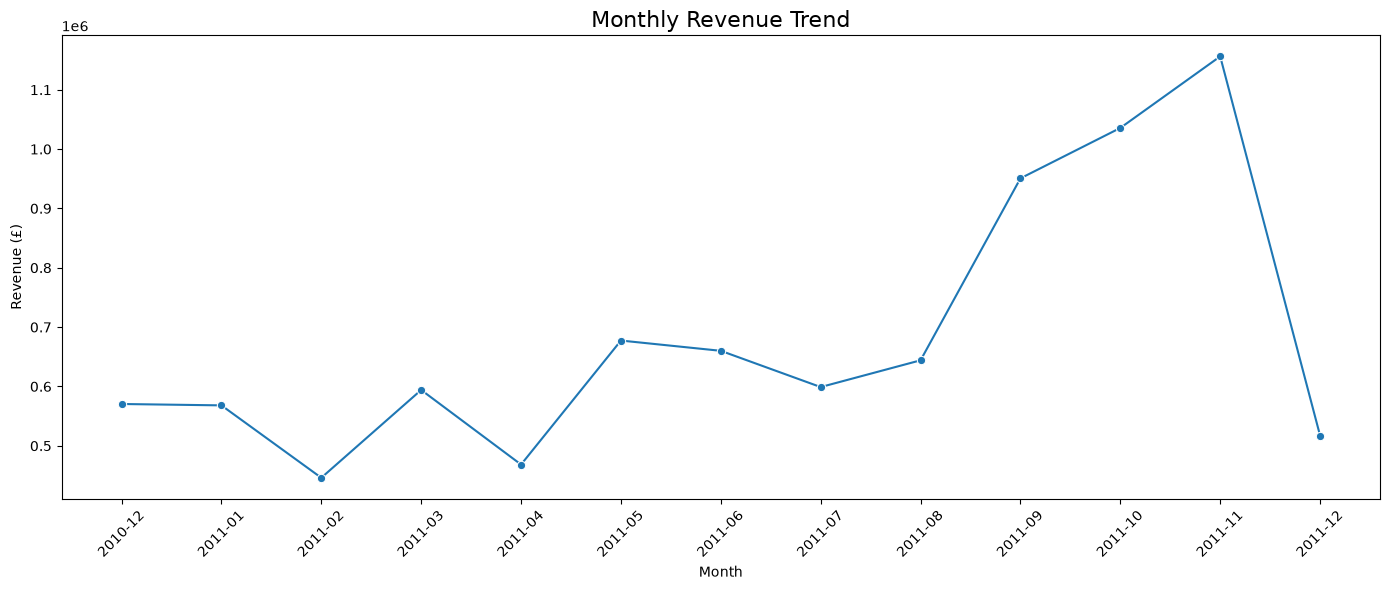

In [31]:
# ============================================
# 25. MONTHLY REVENUE ANALYSIS
# ============================================

# Group transactions by month
# Calculate the total revenue for each month
monthly_revenue = (
    df_clean.groupby(df_clean["InvoiceDate"].dt.to_period("M"))["TotalPrice"]
    .sum()
)

# Convert monthly periods into strings for plotting
monthly_revenue.index = monthly_revenue.index.astype(str)

# Display monthly revenue
print("Monthly Revenue:")
display(monthly_revenue)

# Create a line chart
plt.figure(figsize=(14, 6))

sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker="o"
)

# Add chart title and labels
plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

# Rotate x-axis labels
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Top 10 Highest-Spending Customers:


CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalPrice, dtype: float64

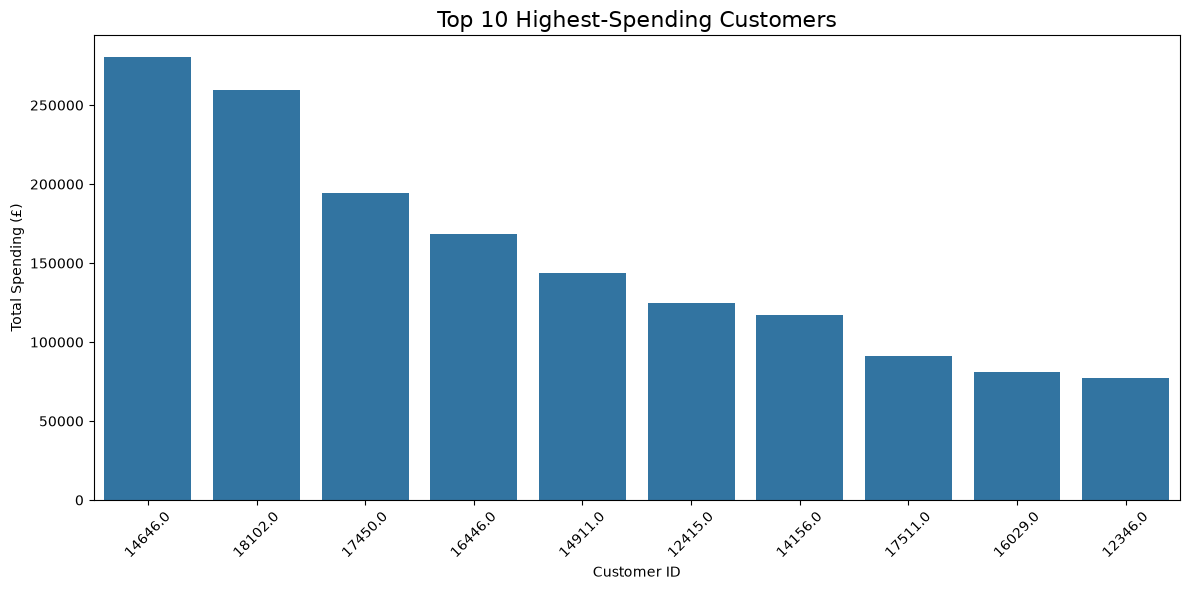

In [32]:
# ============================================
# 26. TOP 10 HIGHEST-SPENDING CUSTOMERS
# ============================================

# Group transactions by CustomerID
# Calculate total spending for each customer
customer_spending = (
    df_clean.groupby("CustomerID")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
)

# Select the top 10 customers
top_customers = customer_spending.head(10)

# Display the results
print("Top 10 Highest-Spending Customers:")
display(top_customers)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_customers.index.astype(str),
    y=top_customers.values
)

# Add chart title and labels
plt.title("Top 10 Highest-Spending Customers", fontsize=16)
plt.xlabel("Customer ID")
plt.ylabel("Total Spending (£)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [33]:
from pathlib import Path
import pandas as pd

# Locate the project root automatically
current_dir = Path.cwd()
possible_roots = [current_dir] + list(current_dir.parents)

project_root = next(
    (
        path for path in possible_roots
        if (path / "app.py").exists()
        and (path / "notebook").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Could not locate the project root.")

# Load the dataset using a relative path
dataset_path = project_root / "dataset" / "Online Retail.xlsx"

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {dataset_path}. "
        "Download it from UCI and place it inside the dataset folder."
    )

df = pd.read_excel(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (541909, 8)


In [34]:
# ============================================
# RECREATE CLEANED DATASET
# ============================================

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Remove transactions with missing Customer IDs
df_clean = df_clean.dropna(subset=["CustomerID"]).copy()

# Remove transactions with zero or negative quantities
df_clean = df_clean[df_clean["Quantity"] > 0].copy()

# Remove transactions with zero or negative prices
df_clean = df_clean[df_clean["UnitPrice"] > 0].copy()

# Reset the DataFrame index
df_clean = df_clean.reset_index(drop=True)

# Calculate total transaction value
df_clean["TotalPrice"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display final dataset information
print("Cleaned dataset recreated successfully!")
print("Final Dataset Shape:", df_clean.shape)

Cleaned dataset recreated successfully!
Final Dataset Shape: (392692, 9)


In [35]:
# Check whether both DataFrames are available
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", df_clean.shape)

Original Dataset: (541909, 8)
Cleaned Dataset: (392692, 9)


In [36]:
# ============================================
# INSPECT HIGH-QUANTITY TRANSACTIONS
# ============================================

# Find transactions with quantities of 10,000 or more
high_quantity_transactions = df_clean[
    df_clean["Quantity"] >= 10000
]

# Display relevant transaction details
display(high_quantity_transactions[[
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "UnitPrice",
    "TotalPrice",
    "CustomerID",
    "InvoiceDate"
]])

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalPrice,CustomerID,InvoiceDate
36521,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346.0,2011-01-18 10:01:00
392226,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0,2011-12-09 09:15:00


In [37]:

# ============================================
# RFM ANALYSIS - CUSTOMER FEATURE ENGINEERING
# ============================================

# Find the latest transaction date in the dataset
latest_date = df_clean["InvoiceDate"].max()

# Set the reference date one day after the latest transaction
reference_date = latest_date + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})

# Rename columns to meaningful RFM names
rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalPrice": "Monetary"
}, inplace=True)

# Display the first five customer records
display(rfm.head())


C:\Users\hp\AppData\Local\Temp\ipykernel_23400\374426885.py:19: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  rfm.rename(columns={


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [38]:
# Display basic statistical information
display(rfm.describe())

# Check dataset dimensions
print("RFM Dataset Shape:", rfm.shape)

# Check for missing values
print("\nMissing Values:")
print(rfm.isnull().sum())

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


RFM Dataset Shape: (4338, 3)

Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


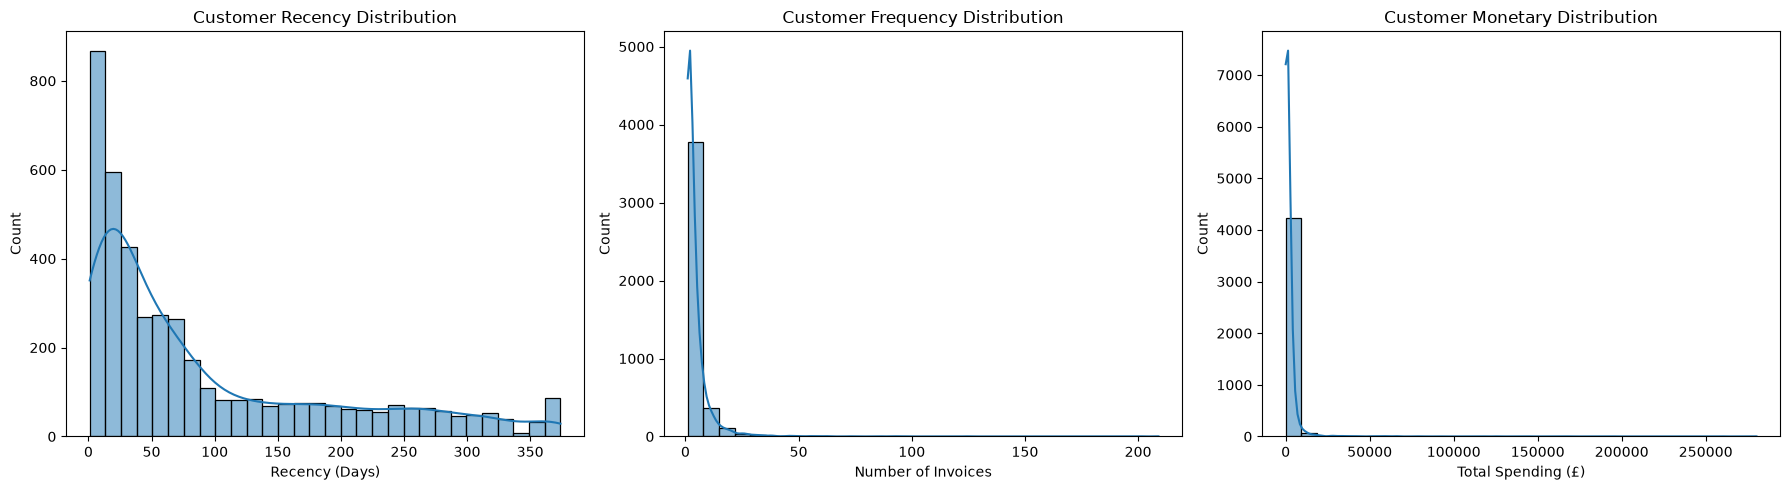

In [39]:

# ============================================
# VISUALISE RFM DISTRIBUTIONS
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Create three plots to examine customer behaviour
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency distribution
sns.histplot(rfm["Recency"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Customer Recency Distribution")
axes[0].set_xlabel("Recency (Days)")

# Frequency distribution
sns.histplot(rfm["Frequency"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Customer Frequency Distribution")
axes[1].set_xlabel("Number of Invoices")

# Monetary distribution
sns.histplot(rfm["Monetary"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Customer Monetary Distribution")
axes[2].set_xlabel("Total Spending (£)")

# Adjust spacing between plots
plt.tight_layout()

# Display the plots
plt.show()


In [40]:

# ============================================
# LOG TRANSFORMATION OF RFM FEATURES
# ============================================

# Create a transformed copy of the RFM dataset
rfm_log = np.log1p(rfm)

# Display the transformed dataset
display(rfm_log.head())

# Compare skewness before and after transformation
print("Skewness Before Transformation:")
print(rfm.skew())

print("\nSkewness After Transformation:")
print(rfm_log.skew())


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,5.789960,0.693147,11.253955
12347.0,1.098612,2.079442,8.368925
12348.0,4.330733,1.609438,7.494564
12349.0,2.995732,0.693147,7.472245
12350.0,5.739793,0.693147,5.815324


Skewness Before Transformation:
Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64

Skewness After Transformation:
Recency     -0.379169
Frequency    1.208652
Monetary     0.396599
dtype: float64


In [41]:

# ============================================
# STANDARDISE RFM FEATURES
# ============================================

from sklearn.preprocessing import StandardScaler

# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler and transform the RFM data
rfm_scaled_array = scaler.fit_transform(rfm_log)

# Convert the scaled array back into a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    columns=rfm_log.columns,
    index=rfm_log.index
)

# Display the scaled RFM dataset
display(rfm_scaled.head())

# Check the mean and standard deviation of each feature
print("\nScaled Feature Means:")
print(rfm_scaled.mean().round(2))

print("\nScaled Feature Standard Deviations:")
print(rfm_scaled.std().round(2))


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.707716
12347.0,-2.038734,1.074425,1.414903
12348.0,0.373104,0.386304,0.720024
12349.0,-0.623086,-0.955214,0.702287
12350.0,1.424558,-0.955214,-0.614514



Scaled Feature Means:
Recency     -0.0
Frequency   -0.0
Monetary    -0.0
dtype: float64

Scaled Feature Standard Deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


In [42]:

# ============================================
# FIND OPTIMAL NUMBER OF CLUSTERS
# ============================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Store the results for different cluster numbers
inertia_values = []
silhouette_scores = []

# Test cluster numbers from 2 to 10
k_values = range(2, 11)

for k in k_values:

    # Create and train the K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Assign customers to clusters
    cluster_labels = kmeans.fit_predict(rfm_scaled)

    # Calculate within-cluster sum of squares
    inertia_values.append(kmeans.inertia_)

    # Calculate Silhouette Score
    score = silhouette_score(rfm_scaled, cluster_labels)
    silhouette_scores.append(score)

# Display the evaluation results
for k, inertia, score in zip(
    k_values, inertia_values, silhouette_scores
):
    print(
        f"K = {k} | "
        f"Inertia = {inertia:.2f} | "
        f"Silhouette Score = {score:.4f}"
    )


K = 2 | Inertia = 6483.59 | Silhouette Score = 0.4328
K = 3 | Inertia = 4869.49 | Silhouette Score = 0.3365
K = 4 | Inertia = 3939.05 | Silhouette Score = 0.3375
K = 5 | Inertia = 3296.71 | Silhouette Score = 0.3162
K = 6 | Inertia = 2855.76 | Silhouette Score = 0.3124
K = 7 | Inertia = 2548.82 | Silhouette Score = 0.3092
K = 8 | Inertia = 2336.34 | Silhouette Score = 0.3033
K = 9 | Inertia = 2156.01 | Silhouette Score = 0.2811
K = 10 | Inertia = 2005.75 | Silhouette Score = 0.2767


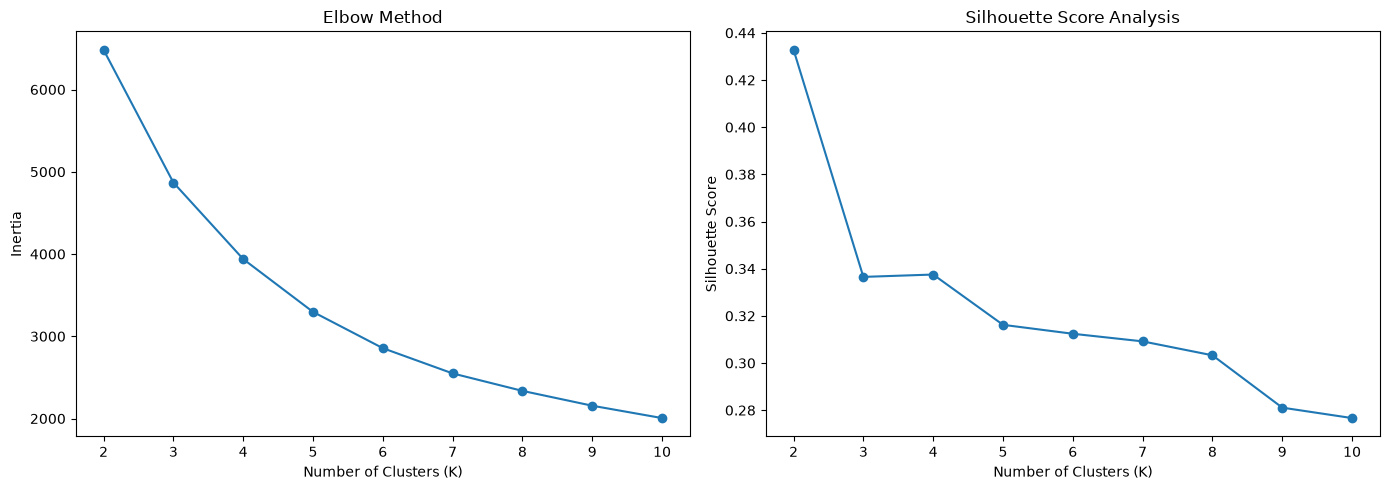

In [43]:

# ============================================
# ELBOW METHOD AND SILHOUETTE ANALYSIS
# ============================================

import matplotlib.pyplot as plt

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method plot
axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

# Silhouette Score plot
axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

axes[1].set_title("Silhouette Score Analysis")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

# Adjust plot spacing
plt.tight_layout()

# Display both plots
plt.show()


In [44]:

# ============================================
# TRAIN FINAL K-MEANS MODEL
# ============================================

from sklearn.cluster import KMeans

# Create the K-Means model with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train the model and assign each customer to a cluster
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Display the first few customer records with cluster labels
display(rfm.head(10))

# Count customers in each cluster
print("\nCustomers in Each Cluster:")
print(rfm["Cluster"].value_counts().sort_index())


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,3
12347.0,2,7,4310.00,0
12348.0,75,4,1797.24,3
12349.0,19,1,1757.55,2
12350.0,310,1,334.40,1
12352.0,36,8,2506.04,3
12353.0,204,1,89.00,1
12354.0,232,1,1079.40,1
12355.0,214,1,459.40,1



Customers in Each Cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [45]:

# ============================================
# CUSTOMER SEGMENT ANALYSIS
# ============================================

# Calculate average RFM values for each cluster
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

# Calculate median RFM values for each cluster
cluster_median = rfm.groupby("Cluster").agg({
    "Recency": "median",
    "Frequency": "median",
    "Monetary": "median"
}).round(2)

# Display average customer behaviour
print("Average RFM Values by Cluster:")
display(cluster_summary)

# Display median customer behaviour
print("Median RFM Values by Cluster:")
display(cluster_median)


Average RFM Values by Cluster:


,Recency,Frequency,Monetary
Cluster,,,
0,12.17,13.75,8088.02
1,181.51,1.32,341.00
2,17.70,2.19,557.32
3,71.64,4.08,1801.78


Median RFM Values by Cluster:


,Recency,Frequency,Monetary
Cluster,,,
0,8.0,10.0,3722.82
1,174.5,1.0,296.09
2,17.0,2.0,480.31
3,57.0,4.0,1345.20


In [46]:

# ============================================
# CUSTOMER DISTRIBUTION BY CLUSTER
# ============================================

# Count customers in each cluster
cluster_counts = rfm["Cluster"].value_counts().sort_index()

# Calculate percentage of total customers
cluster_percentages = (
    cluster_counts / len(rfm) * 100
).round(2)

# Combine the results
cluster_distribution = pd.DataFrame({
    "Customer Count": cluster_counts,
    "Percentage": cluster_percentages
})

display(cluster_distribution)


,Customer Count,Percentage
Cluster,,
0,713,16.44
1,1622,37.39
2,837,19.29
3,1166,26.88


In [47]:
# ============================================
# DISPLAY CUSTOMER SEGMENT RESULTS
# ============================================

# 1. Number of customers in each cluster
print("CUSTOMER COUNT BY CLUSTER")
print(rfm["Cluster"].value_counts().sort_index())

# 2. Average RFM values
print("\nAVERAGE RFM VALUES")
print(rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2).to_string())

# 3. Median RFM values
print("\nMEDIAN RFM VALUES")
print(rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].median().round(2).to_string())

# 4. Percentage of customers in each cluster
print("\nCUSTOMER DISTRIBUTION (%)")
print(
    (rfm["Cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

CUSTOMER COUNT BY CLUSTER
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64

AVERAGE RFM VALUES
         Recency  Frequency  Monetary
Cluster                              
0          12.17      13.75   8088.02
1         181.51       1.32    341.00
2          17.70       2.19    557.32
3          71.64       4.08   1801.78

MEDIAN RFM VALUES
         Recency  Frequency  Monetary
Cluster                              
0            8.0       10.0   3722.82
1          174.5        1.0    296.09
2           17.0        2.0    480.31
3           57.0        4.0   1345.20

CUSTOMER DISTRIBUTION (%)
Cluster
0    16.44
1    37.39
2    19.29
3    26.88
Name: proportion, dtype: float64


In [48]:

# ============================================
# ASSIGN CUSTOMER SEGMENT NAMES
# ============================================

# Define meaningful names for each cluster
segment_names = {
    0: "Champions",
    1: "At-Risk Customers",
    2: "Recent Customers",
    3: "Regular Customers"
}

# Map cluster numbers to customer segment names
rfm["Customer_Segment"] = rfm["Cluster"].map(segment_names)

# Display customer records with their segment names
display(rfm.head(10))

# Count customers in each segment
print("\nCustomer Segment Distribution:")
print(rfm["Customer_Segment"].value_counts())


,Recency,Frequency,Monetary,Cluster,Customer_Segment
CustomerID,,,,,
12346.0,326,1,77183.60,3,Regular Customers
12347.0,2,7,4310.00,0,Champions
12348.0,75,4,1797.24,3,Regular Customers
12349.0,19,1,1757.55,2,Recent Customers
12350.0,310,1,334.40,1,At-Risk Customers
12352.0,36,8,2506.04,3,Regular Customers
12353.0,204,1,89.00,1,At-Risk Customers
12354.0,232,1,1079.40,1,At-Risk Customers
12355.0,214,1,459.40,1,At-Risk Customers



Customer Segment Distribution:
Customer_Segment
At-Risk Customers    1622
Regular Customers    1166
Recent Customers      837
Champions             713
Name: count, dtype: int64


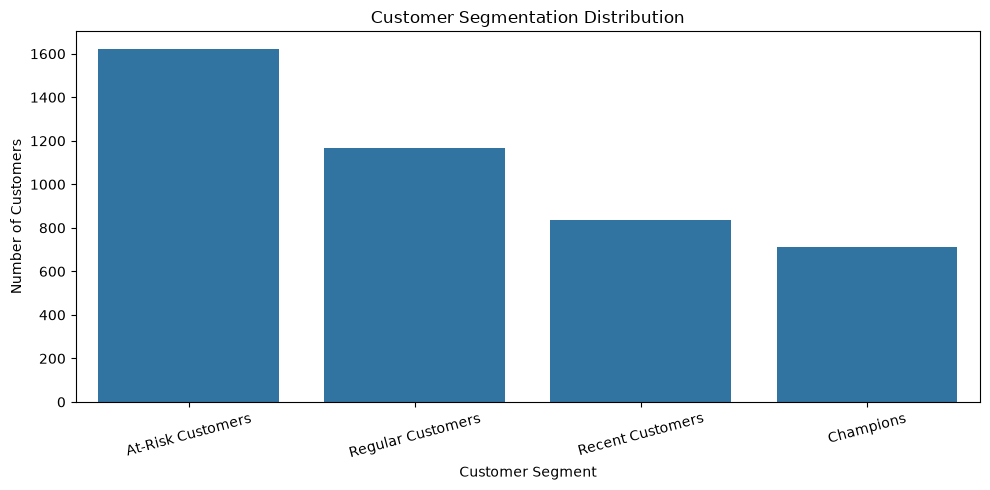

In [49]:

# ============================================
# CUSTOMER SEGMENT DISTRIBUTION
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the number of customers in each segment
segment_counts = rfm["Customer_Segment"].value_counts()

# Create the bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title("Customer Segmentation Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [50]:

# ============================================
# PRODUCT RECOMMENDATION - DATA PREPARATION
# ============================================

import pandas as pd
import numpy as np

from scipy.sparse import csr_matrix

# Extract customer IDs and product codes
customer_codes, customer_ids = pd.factorize(
    df_clean["CustomerID"]
)

product_codes, product_ids = pd.factorize(
    df_clean["StockCode"]
)

# Create a customer-product interaction dataset
interactions = pd.DataFrame({
    "Customer_Code": customer_codes,
    "Product_Code": product_codes
})

# Keep only unique customer-product combinations
interactions = interactions.drop_duplicates()

# Create a sparse product-customer matrix
product_user_matrix = csr_matrix(
    (
        np.ones(len(interactions)),
        (
            interactions["Product_Code"],
            interactions["Customer_Code"]
        )
    ),
    shape=(len(product_ids), len(customer_ids))
)

# Create a product description lookup
product_lookup = (
    df_clean.drop_duplicates(subset="StockCode")
    .set_index("StockCode")["Description"]
)

# Display matrix information
print("Product Recommendation Data Prepared!")
print("Number of Customers:", len(customer_ids))
print("Number of Products:", len(product_ids))
print("Interaction Matrix Shape:", product_user_matrix.shape)
print("Total Customer-Product Interactions:", product_user_matrix.nnz)
print("Matrix Sparsity:", round(
    100 * (1 - product_user_matrix.nnz /
          (product_user_matrix.shape[0] * product_user_matrix.shape[1])),
    2
), "%")


Product Recommendation Data Prepared!
Number of Customers: 4338
Number of Products: 3665
Interaction Matrix Shape: (3665, 4338)
Total Customer-Product Interactions: 266792
Matrix Sparsity: 98.32 %


In [51]:

# ============================================
# PRODUCT SIMILARITY MODEL
# ============================================

from sklearn.neighbors import NearestNeighbors

# Create the product similarity model
product_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=6
)

# Train the model using the product-customer matrix
product_model.fit(product_user_matrix)

print("Product similarity model trained successfully!")


Product similarity model trained successfully!


In [52]:

# ============================================
# PRODUCT RECOMMENDATION FUNCTION
# ============================================

def recommend_products(product_code, n_recommendations=5):

    # Find the position of the selected product
    product_position = np.where(
        product_ids == product_code
    )[0]

    # Check whether the product exists
    if len(product_position) == 0:
        print("Product not found!")
        return pd.DataFrame()

    # Get the purchase pattern of the selected product
    product_vector = product_user_matrix[
        product_position[0]
    ]

    # Find the nearest products
    distances, indices = product_model.kneighbors(
        product_vector,
        n_neighbors=n_recommendations + 1
    )

    # Store the recommended products
    recommendations = []

    for distance, index in zip(
        distances.flatten(),
        indices.flatten()
    ):

        # Skip the selected product itself
        if index == product_position[0]:
            continue

        # Get the recommended product code
        recommended_code = product_ids[index]

        # Calculate cosine similarity
        similarity = 1 - distance

        # Get the product description
        description = product_lookup.get(
            recommended_code,
            "Description unavailable"
        )

        recommendations.append({
            "Product Code": recommended_code,
            "Description": description,
            "Similarity Score": round(float(similarity), 4)
        })

        # Stop after reaching the requested number
        if len(recommendations) == n_recommendations:
            break

    return pd.DataFrame(recommendations)


In [53]:

# ============================================
# TEST PRODUCT RECOMMENDATIONS
# ============================================

# Find the product with the most unique customer purchases
product_popularity = interactions["Product_Code"].value_counts()

# Get the most popular product's position
popular_product_position = product_popularity.index[0]

# Convert its position back to the original product code
test_product_code = product_ids[popular_product_position]

# Display the selected product
print("Selected Product:")
print("Product Code:", test_product_code)
print("Description:", product_lookup.get(test_product_code))

# Generate five product recommendations
recommendations = recommend_products(
    test_product_code,
    n_recommendations=5
)

print("\nRecommended Products:")
display(recommendations)


Selected Product:
Product Code: 22423
Description: REGENCY CAKESTAND 3 TIER

Recommended Products:


,Product Code,Description,Similarity Score
0,22699,ROSES REGENCY TEACUP AND SAUCER,0.5258
1,22697,GREEN REGENCY TEACUP AND SAUCER,0.5086
2,22698,PINK REGENCY TEACUP AND SAUCER,0.4886
3,23245,SET OF 3 REGENCY CAKE TINS,0.4668
4,23173,REGENCY TEAPOT ROSES,0.4535


In [54]:

# ============================================
# TEST RECOMMENDATIONS FOR MULTIPLE PRODUCTS
# ============================================

# Find the five most frequently purchased products
top_products = (
    interactions["Product_Code"]
    .value_counts()
    .head(5)
    .index
)

# Generate recommendations for each product
for position in top_products:

    # Convert product position to its original stock code
    selected_code = product_ids[position]

    # Get product description
    selected_description = product_lookup.get(
        selected_code,
        "Description unavailable"
    )

    print("\n" + "=" * 65)
    print("SELECTED PRODUCT:", selected_description)
    print("PRODUCT CODE:", selected_code)
    print("=" * 65)

    # Generate recommendations
    result = recommend_products(
        selected_code,
        n_recommendations=5
    )

    display(result)



SELECTED PRODUCT: REGENCY CAKESTAND 3 TIER
PRODUCT CODE: 22423


,Product Code,Description,Similarity Score
0,22699,ROSES REGENCY TEACUP AND SAUCER,0.5258
1,22697,GREEN REGENCY TEACUP AND SAUCER,0.5086
2,22698,PINK REGENCY TEACUP AND SAUCER,0.4886
3,23245,SET OF 3 REGENCY CAKE TINS,0.4668
4,23173,REGENCY TEAPOT ROSES,0.4535



SELECTED PRODUCT: WHITE HANGING HEART T-LIGHT HOLDER
PRODUCT CODE: 85123A


,Product Code,Description,Similarity Score
0,21733,RED HANGING HEART T-LIGHT HOLDER,0.5435
1,22804,CANDLEHOLDER PINK HANGING HEART,0.4931
2,22470,HEART OF WICKER LARGE,0.4113
3,22469,HEART OF WICKER SMALL,0.3798
4,82482,WOODEN PICTURE FRAME WHITE FINISH,0.3629



SELECTED PRODUCT: PARTY BUNTING
PRODUCT CODE: 47566


,Product Code,Description,Similarity Score
0,23298,SPOTTY BUNTING,0.4710
1,47566B,TEA TIME PARTY BUNTING,0.3797
2,22423,REGENCY CAKESTAND 3 TIER,0.3495
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.3276
4,84879,ASSORTED COLOUR BIRD ORNAMENT,0.3017



SELECTED PRODUCT: ASSORTED COLOUR BIRD ORNAMENT
PRODUCT CODE: 84879


,Product Code,Description,Similarity Score
0,21136,PAINTED METAL PEARS ASSORTED,0.4940
1,22423,REGENCY CAKESTAND 3 TIER,0.3235
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.3111
3,47566,PARTY BUNTING,0.3017
4,21754,HOME BUILDING BLOCK WORD,0.3016



SELECTED PRODUCT: SET OF 3 CAKE TINS PANTRY DESIGN 
PRODUCT CODE: 22720


,Product Code,Description,Similarity Score
0,22722,SET OF 6 SPICE TINS PANTRY DESIGN,0.5424
1,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,0.5292
2,22666,RECIPE BOX PANTRY YELLOW DESIGN,0.4827
3,22960,JAM MAKING SET WITH JARS,0.4128
4,23245,SET OF 3 REGENCY CAKE TINS,0.4094


In [55]:

# ============================================
# CUSTOMER-SPECIFIC RECOMMENDATION FUNCTION
# ============================================

def recommend_for_customer(customer_id, n_recommendations=5):

    # Find all products purchased by the customer
    purchased_products = df_clean.loc[
        df_clean["CustomerID"] == customer_id,
        "StockCode"
    ].unique()

    # Check whether the customer exists
    if len(purchased_products) == 0:
        print("Customer not found!")
        return pd.DataFrame()

    # Store similarity scores for candidate products
    recommendation_scores = {}

    # Find similar products for every purchased product
    for product_code in purchased_products:

        # Get recommendations for the purchased product
        similar_products = recommend_products(
            product_code,
            n_recommendations=10
        )

        # Combine similarity scores
        for _, row in similar_products.iterrows():

            recommended_code = row["Product Code"]
            similarity = row["Similarity Score"]

            recommendation_scores[recommended_code] = (
                recommendation_scores.get(recommended_code, 0)
                + similarity
            )

    # Exclude products the customer has already purchased
    for product_code in purchased_products:
        recommendation_scores.pop(product_code, None)

    # Sort products by combined similarity score
    top_recommendations = sorted(
        recommendation_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )[:n_recommendations]

    # Prepare recommendation results
    results = []

    for product_code, score in top_recommendations:

        results.append({
            "Product Code": product_code,
            "Description": product_lookup.get(
                product_code,
                "Description unavailable"
            ),
            "Recommendation Score": round(score, 4)
        })

    return pd.DataFrame(results)


In [56]:

# ============================================
# TEST CUSTOMER-SPECIFIC RECOMMENDATIONS
# ============================================

# Select one customer from the Champions segment
champion_customer = rfm[
    rfm["Customer_Segment"] == "Champions"
].index[0]

# Display customer information
print("Customer ID:", champion_customer)
print("Customer Segment:", rfm.loc[
    champion_customer, "Customer_Segment"
])

# Display personalised recommendations
customer_recommendations = recommend_for_customer(
    champion_customer,
    n_recommendations=5
)

print("\nPersonalised Product Recommendations:")
display(customer_recommendations)


Customer ID: 12347.0
Customer Segment: Champions

Personalised Product Recommendations:


,Product Code,Description,Recommendation Score
0,23245,SET OF 3 REGENCY CAKE TINS,4.4500
1,22730,ALARM CLOCK BAKELIKE IVORY,3.0806
2,21212,PACK OF 72 RETROSPOT CAKE CASES,3.0691
3,21977,PACK OF 60 PINK PAISLEY CAKE CASES,2.5622
4,22951,60 CAKE CASES DOLLY GIRL DESIGN,2.4542


In [57]:

# Check whether the variables required for recommendation testing exist

required_variables = [
    "df_clean",
    "interactions",
    "product_ids",
    "product_lookup",
    "product_model",
    "recommend_products",
    "rfm"
]

for variable in required_variables:
    if variable in globals():
        print(f"{variable}: Available")
    else:
        print(f"{variable}: Missing")


df_clean: Available
interactions: Available
product_ids: Available
product_lookup: Available
product_model: Available
recommend_products: Available
rfm: Available


In [58]:

# Identify the five most frequently purchased products
top_products = (
    interactions["Product_Code"]
    .value_counts()
    .head(5)
    .index
)

# Generate recommendations for each selected product
for position in top_products:

    selected_code = product_ids[position]

    selected_description = product_lookup.get(
        selected_code,
        "Description unavailable"
    )

    print("\n" + "=" * 65)
    print("SELECTED PRODUCT:", selected_description)
    print("PRODUCT CODE:", selected_code)
    print("=" * 65)

    result = recommend_products(
        selected_code,
        n_recommendations=5
    )

    display(result)



SELECTED PRODUCT: REGENCY CAKESTAND 3 TIER
PRODUCT CODE: 22423


,Product Code,Description,Similarity Score
0,22699,ROSES REGENCY TEACUP AND SAUCER,0.5258
1,22697,GREEN REGENCY TEACUP AND SAUCER,0.5086
2,22698,PINK REGENCY TEACUP AND SAUCER,0.4886
3,23245,SET OF 3 REGENCY CAKE TINS,0.4668
4,23173,REGENCY TEAPOT ROSES,0.4535



SELECTED PRODUCT: WHITE HANGING HEART T-LIGHT HOLDER
PRODUCT CODE: 85123A


,Product Code,Description,Similarity Score
0,21733,RED HANGING HEART T-LIGHT HOLDER,0.5435
1,22804,CANDLEHOLDER PINK HANGING HEART,0.4931
2,22470,HEART OF WICKER LARGE,0.4113
3,22469,HEART OF WICKER SMALL,0.3798
4,82482,WOODEN PICTURE FRAME WHITE FINISH,0.3629



SELECTED PRODUCT: PARTY BUNTING
PRODUCT CODE: 47566


,Product Code,Description,Similarity Score
0,23298,SPOTTY BUNTING,0.4710
1,47566B,TEA TIME PARTY BUNTING,0.3797
2,22423,REGENCY CAKESTAND 3 TIER,0.3495
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.3276
4,84879,ASSORTED COLOUR BIRD ORNAMENT,0.3017



SELECTED PRODUCT: ASSORTED COLOUR BIRD ORNAMENT
PRODUCT CODE: 84879


,Product Code,Description,Similarity Score
0,21136,PAINTED METAL PEARS ASSORTED,0.4940
1,22423,REGENCY CAKESTAND 3 TIER,0.3235
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.3111
3,47566,PARTY BUNTING,0.3017
4,21754,HOME BUILDING BLOCK WORD,0.3016



SELECTED PRODUCT: SET OF 3 CAKE TINS PANTRY DESIGN 
PRODUCT CODE: 22720


,Product Code,Description,Similarity Score
0,22722,SET OF 6 SPICE TINS PANTRY DESIGN,0.5424
1,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,0.5292
2,22666,RECIPE BOX PANTRY YELLOW DESIGN,0.4827
3,22960,JAM MAKING SET WITH JARS,0.4128
4,23245,SET OF 3 REGENCY CAKE TINS,0.4094


In [59]:

# Select one customer from the Champions segment
champion_customer = rfm[
    rfm["Customer_Segment"] == "Champions"
].index[0]

# Display customer information
print("Customer ID:", champion_customer)

print(
    "Customer Segment:",
    rfm.loc[champion_customer, "Customer_Segment"]
)

print(
    "Total Invoices:",
    rfm.loc[champion_customer, "Frequency"]
)

print(
    "Total Spending: £",
    round(rfm.loc[champion_customer, "Monetary"], 2)
)


Customer ID: 12347.0
Customer Segment: Champions
Total Invoices: 7
Total Spending: £ 4310.0


In [60]:

# Generate personalised recommendations for this customer
customer_recommendations = recommend_for_customer(
    champion_customer,
    n_recommendations=5
)

print("\nPersonalised Product Recommendations:")
display(customer_recommendations)



Personalised Product Recommendations:


,Product Code,Description,Recommendation Score
0,23245,SET OF 3 REGENCY CAKE TINS,4.4500
1,22730,ALARM CLOCK BAKELIKE IVORY,3.0806
2,21212,PACK OF 72 RETROSPOT CAKE CASES,3.0691
3,21977,PACK OF 60 PINK PAISLEY CAKE CASES,2.5622
4,22951,60 CAKE CASES DOLLY GIRL DESIGN,2.4542


In [61]:

# Get all products already purchased by this customer
purchased_products = set(
    df_clean.loc[
        df_clean["CustomerID"] == champion_customer,
        "StockCode"
    ].astype(str)
)

# Get the recommended products
recommended_products = set(
    customer_recommendations["Product Code"].astype(str)
)

# Check whether any recommended products were already purchased
already_purchased = purchased_products.intersection(
    recommended_products
)

print("Products previously purchased:", len(purchased_products))
print("Products recommended:", len(recommended_products))
print("Already purchased recommendations:", len(already_purchased))

if len(already_purchased) == 0:
    print("\nPASS: All recommendations are new to this customer.")
else:
    print("\nWARNING: Some recommendations were already purchased.")
    print("Product codes:", already_purchased)


Products previously purchased: 103
Products recommended: 5
Already purchased recommendations: 0

PASS: All recommendations are new to this customer.


In [62]:

# Check the date range covered by our cleaned dataset
print("First transaction:", df_clean["InvoiceDate"].min())
print("Last transaction:", df_clean["InvoiceDate"].max())

# Count the number of unique invoices
print("Total invoices:", df_clean["InvoiceNo"].nunique())

# Count unique customers
print("Total customers:", df_clean["CustomerID"].nunique())


First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00
Total invoices: 18532
Total customers: 4338


In [63]:

# Define the date for separating training and testing data
split_date = pd.Timestamp("2011-11-09")

# Create training data using earlier transactions
train_df = df_clean[
    df_clean["InvoiceDate"] < split_date
].copy()

# Create testing data using the final 30 days
test_df = df_clean[
    df_clean["InvoiceDate"] >= split_date
].copy()

# Display the dataset sizes
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining date range:")
print(train_df["InvoiceDate"].min(), "to", train_df["InvoiceDate"].max())

print("\nTesting date range:")
print(test_df["InvoiceDate"].min(), "to", test_df["InvoiceDate"].max())

print("\nTraining customers:", train_df["CustomerID"].nunique())
print("Testing customers:", test_df["CustomerID"].nunique())


Training records: 327561
Testing records: 65131

Training date range:
2010-12-01 08:26:00 to 2011-11-08 17:42:00

Testing date range:
2011-11-09 08:11:00 to 2011-12-09 12:50:00

Training customers: 4067
Testing customers: 1667


In [64]:

from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# Create unique customer-product interactions from training data
train_interactions = train_df[
    ["CustomerID", "StockCode"]
].drop_duplicates().copy()

# Assign numerical IDs to customers and products
train_customer_codes, train_customer_ids = pd.factorize(
    train_interactions["CustomerID"]
)

train_product_codes, train_product_ids = pd.factorize(
    train_interactions["StockCode"]
)

# Build the training interaction matrix
train_product_user_matrix = csr_matrix(
    (
        np.ones(len(train_interactions)),
        (train_product_codes, train_customer_codes)
    ),
    shape=(
        len(train_product_ids),
        len(train_customer_ids)
    )
)

# Train the recommendation model using training data only
train_product_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=6
)

train_product_model.fit(train_product_user_matrix)

# Create a product description lookup from training data only
train_product_lookup = (
    train_df.drop_duplicates(subset="StockCode")
    .set_index("StockCode")["Description"]
)

print("Training interaction matrix:", train_product_user_matrix.shape)
print("Training customers:", len(train_customer_ids))
print("Training products:", len(train_product_ids))
print("Training interactions:", train_product_matrix_count if False else len(train_interactions))


Training interaction matrix: (3624, 4067)
Training customers: 4067
Training products: 3624
Training interactions: 231178


In [65]:

def recommend_from_training(product_code, n_recommendations=5):

    # Find the numerical position of the selected product
    product_position = np.where(
        train_product_ids == product_code
    )[0]

    # Return an empty list if the product is not in training data
    if len(product_position) == 0:
        return []

    # Get the selected product's interaction vector
    product_vector = train_product_user_matrix[
        product_position[0]
    ]

    # Find similar products
    distances, indices = train_product_model.kneighbors(
        product_vector,
        n_neighbors=min(
            n_recommendations + 1,
            len(train_product_ids)
        )
    )

    recommendations = []

    for distance, index in zip(
        distances.flatten(),
        indices.flatten()
    ):

        # Exclude the selected product itself
        if index == product_position[0]:
            continue

        # Convert numerical position back to product code
        recommended_code = train_product_ids[index]

        recommendations.append({
            "Product Code": recommended_code,
            "Similarity": 1 - float(distance)
        })

        if len(recommendations) == n_recommendations:
            break

    return recommendations


In [66]:

# Create purchase history for each customer
train_customer_products = (
    train_df.groupby("CustomerID")["StockCode"]
    .apply(set)
    .to_dict()
)

test_customer_products = (
    test_df.groupby("CustomerID")["StockCode"]
    .apply(set)
    .to_dict()
)

# Map each training product to its matrix position
product_to_position = {
    code: position
    for position, code in enumerate(train_product_ids)
}

# Identify products that existed in the training catalogue
training_catalogue = set(train_product_ids)

# Identify customers with both training and testing purchases
common_customers = (
    set(train_customer_products)
    .intersection(set(test_customer_products))
)

# Keep customers with at least one new, recommendable future purchase
evaluation_customers = []

for customer_id in common_customers:

    relevant_products = (
        test_customer_products[customer_id]
        .intersection(training_catalogue)
        .difference(train_customer_products[customer_id])
    )

    if relevant_products:
        evaluation_customers.append(customer_id)

# Select up to 300 customers for evaluation
evaluation_sample = (
    pd.Series(evaluation_customers)
    .sample(
        n=min(300, len(evaluation_customers)),
        random_state=42
    )
    .tolist()
)

print("Customers eligible for evaluation:", len(evaluation_customers))
print("Customers selected for evaluation:", len(evaluation_sample))


# Generate recommendations using only training purchases
def recommend_for_evaluation(customer_id, n_recommendations=5):

    purchased = train_customer_products[customer_id]

    # Convert previously purchased products into matrix positions
    seed_positions = [
        product_to_position[code]
        for code in purchased
        if code in product_to_position
    ]

    if not seed_positions:
        return []

    # Find similar products for all products in the customer's history
    distances, indices = train_product_model.kneighbors(
        train_product_user_matrix[seed_positions],
        n_neighbors=min(11, len(train_product_ids))
    )

    recommendation_scores = {}

    # Combine similarity scores from the customer's purchase history
    for row_number, seed_position in enumerate(seed_positions):

        for distance, index in zip(
            distances[row_number],
            indices[row_number]
        ):

            # Exclude the original product
            if index == seed_position:
                continue

            recommended_code = train_product_ids[index]

            # Exclude products already purchased by this customer
            if recommended_code in purchased:
                continue

            similarity = max(0, 1 - float(distance))

            recommendation_scores[recommended_code] = (
                recommendation_scores.get(recommended_code, 0)
                + similarity
            )

    # Return the five products with the highest combined scores
    ranked_products = sorted(
        recommendation_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )

    return [
        product_code
        for product_code, score in ranked_products[:n_recommendations]
    ]


# Calculate Precision@5 and Recall@5
precision_scores = []
recall_scores = []
recommended_product_set = set()

for customer_id in evaluation_sample:

    actual_products = (
        test_customer_products[customer_id]
        .intersection(training_catalogue)
        .difference(train_customer_products[customer_id])
    )

    recommendations = recommend_for_evaluation(
        customer_id,
        n_recommendations=5
    )

    recommended_product_set.update(recommendations)

    # Count how many recommendations were actually purchased
    hits = len(set(recommendations).intersection(actual_products))

    precision_scores.append(hits / 5)
    recall_scores.append(hits / len(actual_products))


# Display the evaluation results
print("\nRECOMMENDATION MODEL EVALUATION")
print("=" * 45)

print(
    "Average Precision@5:",
    round(np.mean(precision_scores), 4)
)

print(
    "Average Recall@5:",
    round(np.mean(recall_scores), 4)
)

print(
    "Recommendation Catalogue Coverage:",
    round(
        len(recommended_product_set) / len(training_catalogue) * 100,
        2
    ),
    "%"
)

print("Customers evaluated:", len(precision_scores))


Customers eligible for evaluation: 1288
Customers selected for evaluation: 300

RECOMMENDATION MODEL EVALUATION
Average Precision@5: 0.0667
Average Recall@5: 0.0295
Recommendation Catalogue Coverage: 11.81 %
Customers evaluated: 300


In [67]:

# Count how many different customers purchased each product
product_popularity = (
    train_interactions.groupby("StockCode")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
)

# Rank products from most to least popular
popular_products = product_popularity.index.tolist()


# Generate recommendations using popularity alone
def recommend_popular_products(customer_id, n_recommendations=5):

    # Products already purchased by this customer
    purchased = train_customer_products[customer_id]

    # Select popular products the customer has not purchased
    recommendations = [
        product
        for product in popular_products
        if product not in purchased
    ]

    return recommendations[:n_recommendations]


# Evaluate the popularity baseline on the same customers
baseline_precision = []
baseline_recall = []
baseline_recommended_products = set()

for customer_id in evaluation_sample:

    actual_products = (
        test_customer_products[customer_id]
        .intersection(training_catalogue)
        .difference(train_customer_products[customer_id])
    )

    recommendations = recommend_popular_products(
        customer_id,
        n_recommendations=5
    )

    baseline_recommended_products.update(recommendations)

    hits = len(set(recommendations).intersection(actual_products))

    baseline_precision.append(hits / 5)
    baseline_recall.append(hits / len(actual_products))


# Display baseline results
print("POPULARITY BASELINE EVALUATION")
print("=" * 45)

print(
    "Average Precision@5:",
    round(np.mean(baseline_precision), 4)
)

print(
    "Average Recall@5:",
    round(np.mean(baseline_recall), 4)
)

print(
    "Recommendation Catalogue Coverage:",
    round(
        len(baseline_recommended_products) / len(training_catalogue) * 100,
        2
    ),
    "%"
)


POPULARITY BASELINE EVALUATION
Average Precision@5: 0.032
Average Recall@5: 0.0107
Recommendation Catalogue Coverage: 0.8 %


In [68]:

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Use the existing four-cluster assignments
cluster_labels = rfm["Cluster"]

# Calculate clustering evaluation metrics
silhouette = silhouette_score(
    rfm_scaled,
    cluster_labels
)

davies_bouldin = davies_bouldin_score(
    rfm_scaled,
    cluster_labels
)

calinski_harabasz = calinski_harabasz_score(
    rfm_scaled,
    cluster_labels
)

# Display results
print("K-MEANS CLUSTERING EVALUATION")
print("=" * 45)

print("Number of clusters:", cluster_labels.nunique())
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(davies_bouldin, 4))
print("Calinski-Harabasz Score:", round(calinski_harabasz, 2))


K-MEANS CLUSTERING EVALUATION
Number of clusters: 4
Silhouette Score: 0.3375
Davies-Bouldin Index: 1.0086
Calinski-Harabasz Score: 3328.34


In [69]:

# ============================================
# INTEGRATED CUSTOMER ANALYSIS
# ============================================

def analyze_customer(customer_id, n_recommendations=5):

    # Check whether the customer exists in our RFM dataset
    if customer_id not in rfm.index:
        print("Customer ID not found!")
        return

    # Retrieve the customer's RFM profile and segment
    customer_profile = rfm.loc[customer_id]

    recency = customer_profile["Recency"]
    frequency = customer_profile["Frequency"]
    monetary = customer_profile["Monetary"]
    segment = customer_profile["Customer_Segment"]

    # Retrieve products previously purchased by this customer
    purchased_products = set(
        df_clean.loc[
            df_clean["CustomerID"] == customer_id,
            "StockCode"
        ]
    )

    # Convert purchased products into matrix positions
    seed_positions = [
        np.where(product_ids == code)[0][0]
        for code in purchased_products
        if code in product_ids
    ]

    # Find similar products and calculate recommendation scores
    recommendation_scores = {}

    if seed_positions:
        distances, indices = product_model.kneighbors(
            product_user_matrix[seed_positions],
            n_neighbors=min(11, len(product_ids))
        )

        for row_number, seed_position in enumerate(seed_positions):

            for distance, index in zip(
                distances[row_number],
                indices[row_number]
            ):

                # Skip the original product
                if index == seed_position:
                    continue

                recommended_code = product_ids[index]

                # Do not recommend products already purchased
                if recommended_code in purchased_products:
                    continue

                similarity = max(0, 1 - float(distance))

                recommendation_scores[recommended_code] = (
                    recommendation_scores.get(recommended_code, 0)
                    + similarity
                )

    # Rank products by their recommendation scores
    ranked_products = sorted(
        recommendation_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )

    # Prepare the recommendation results
    recommendations = []

    for product_code, score in ranked_products[:n_recommendations]:

        recommendations.append({
            "Product Code": product_code,
            "Description": product_lookup.get(
                product_code,
                "Description unavailable"
            ),
            "Recommendation Score": round(score, 4)
        })

    recommendations_df = pd.DataFrame(recommendations)

    # Suggest a business action based on the customer segment
    business_actions = {
        "Champions": "Offer loyalty rewards and exclusive products.",
        "At-Risk Customers": "Launch re-engagement campaigns and special offers.",
        "Recent Customers": "Encourage repeat purchases through product bundles.",
        "Regular Customers": "Promote complementary products and loyalty benefits."
    }

    # Display the complete customer analysis
    print("CUSTOMER ANALYSIS")
    print("=" * 50)

    print("Customer ID:", customer_id)
    print("Customer Segment:", segment)
    print("Recency:", recency, "days")
    print("Frequency:", frequency, "invoices")
    print("Monetary: £", round(monetary, 2))

    print("\nPURCHASE HISTORY")
    print("=" * 50)
    print("Previously purchased products:", len(purchased_products))

    print("\nPERSONALISED PRODUCT RECOMMENDATIONS")
    print("=" * 50)

    display(recommendations_df)

    print("\nSUGGESTED BUSINESS ACTION")
    print("=" * 50)
    print(business_actions.get(segment, "Review customer behaviour."))

    return None


In [70]:

# Test the integrated customer analysis
analyze_customer(12347.0)


CUSTOMER ANALYSIS
Customer ID: 12347.0
Customer Segment: Champions
Recency: 2 days
Frequency: 7 invoices
Monetary: £ 4310.0

PURCHASE HISTORY
Previously purchased products: 103

PERSONALISED PRODUCT RECOMMENDATIONS


,Product Code,Description,Recommendation Score
0,23245,SET OF 3 REGENCY CAKE TINS,4.4500
1,22730,ALARM CLOCK BAKELIKE IVORY,3.0805
2,21212,PACK OF 72 RETROSPOT CAKE CASES,3.0692
3,21977,PACK OF 60 PINK PAISLEY CAKE CASES,2.5621
4,22951,60 CAKE CASES DOLLY GIRL DESIGN,2.4542



SUGGESTED BUSINESS ACTION
Offer loyalty rewards and exclusive products.


In [71]:
from pathlib import Path
import joblib

# Create the models folder in the project root
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Collect all required artifacts
artifacts = {
    "rfm": rfm,
    "df_clean": df_clean,
    "product_model": product_model,
    "product_user_matrix": product_user_matrix,
    "product_ids": product_ids,
    "product_lookup": product_lookup
}

# Save the artifacts
artifact_path = models_dir / "customer_recommendation_artifacts.joblib"

joblib.dump(artifacts, artifact_path, compress=3)

print("Model artifacts saved successfully!")
print("Saved location:", artifact_path)
print("File size:", round(artifact_path.stat().st_size / (1024 * 1024), 2), "MB")

Model artifacts saved successfully!
Saved location: E:\Projects\AI Customer Segmentation\models\customer_recommendation_artifacts.joblib
File size: 4.95 MB


In [72]:
print("CUSTOMER IDs FOR DASHBOARD TESTING")
print("=" * 45)

for segment in [
    "Champions",
    "At-Risk Customers",
    "Recent Customers",
    "Regular Customers"
]:
    customer_id = rfm[
        rfm["Customer_Segment"] == segment
    ].index[0]

    print(f"{segment}: {customer_id}")

CUSTOMER IDs FOR DASHBOARD TESTING
Champions: 12347.0
At-Risk Customers: 12350.0
Recent Customers: 12349.0
Regular Customers: 12346.0


In [73]:
import joblib

loaded_artifacts = joblib.load(artifact_path)

print("Available artifacts:")
for key in loaded_artifacts.keys():
    print("-", key)

print("\nTotal artifacts:", len(loaded_artifacts))

Available artifacts:
- rfm
- df_clean
- product_model
- product_user_matrix
- product_ids
- product_lookup

Total artifacts: 6
